# Pairs Trading Workshop: Cointegration, Mean Reversion & Leak-Free Backtesting

**Target Audience:** CS & Data Science undergraduates (`numpy`, `pandas`, `statsmodels`, `matplotlib`)

### Learning Objectives
1. Distinguish **Pearson correlation** from **cointegration** and see why high correlation alone fails.
2. Construct a hedge ratio ($\hat{\beta}$) via OLS, test for cointegration (Engle-Granger two-step + ADF), and estimate half-life ($t_{1/2}$).
3. Build a leak-free rolling z-score strategy with explicit execution lags and transaction cost accounting.
4. Stress-test the strategy against a structural break and complete a 15-minute parameter & cost sensitivity challenge.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller

plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)

def load_workshop_universe(n_days: int = 750, seed: int = 42) -> pd.DataFrame:
    """
    Generates a self-contained 10-asset daily price universe for offline/live workshops.
    Includes:
      - (ASSET_A1, ASSET_A2): Cointegrated pair with fast mean reversion
      - (ASSET_B1, ASSET_B2): Cointegrated pair with moderate mean reversion
      - (ASSET_C1, ASSET_C2): High-correlation non-cointegrated pair (drifting spread)
      - ASSET_D1..D4: Additional sector peers
    """
    rng = np.random.default_rng(seed)
    dates = pd.bdate_range(start='2023-01-03', periods=n_days)

    # Common sector factor (random walk)
    sector_shock = rng.normal(0.0002, 0.014, size=n_days)
    common_factor = np.cumsum(sector_shock)

    # Pair A: Cointegrated (beta = 1.25, half-life ~ 8 days)
    spread_a = np.zeros(n_days)
    for t in range(1, n_days):
        spread_a[t] = 0.91 * spread_a[t - 1] + rng.normal(0, 0.015)
    log_a2 = 4.2 + 0.85 * common_factor + np.cumsum(rng.normal(0.0001, 0.005, n_days))
    log_a1 = 0.5 + 1.25 * log_a2 + spread_a

    # Pair B: Cointegrated (beta = 0.80, half-life ~ 15 days)
    spread_b = np.zeros(n_days)
    for t in range(1, n_days):
        spread_b[t] = 0.955 * spread_b[t - 1] + rng.normal(0, 0.014)
    log_b2 = 3.9 + 0.90 * common_factor + np.cumsum(rng.normal(0.0001, 0.005, n_days))
    log_b1 = 0.3 + 0.80 * log_b2 + spread_b

    # Pair C: High correlation (common factor), NO cointegration (random walk divergence)
    log_c2 = 4.5 + 1.15 * common_factor + np.cumsum(rng.normal(0.0001, 0.004, n_days))
    log_c1 = 0.2 + 1.10 * log_c2 + np.cumsum(rng.normal(0.0, 0.012, n_days))

    log_prices = pd.DataFrame({
        'ASSET_A1': log_a1,
        'ASSET_A2': log_a2,
        'ASSET_B1': log_b1,
        'ASSET_B2': log_b2,
        'ASSET_C1': log_c1,
        'ASSET_C2': log_c2,
        'ASSET_D1': 4.0 + 0.8 * common_factor + np.cumsum(rng.normal(0.0, 0.010, n_days)),
        'ASSET_D2': 4.1 + 0.75 * common_factor + np.cumsum(rng.normal(0.0, 0.011, n_days)),
        'ASSET_D3': 3.8 + 0.95 * common_factor + np.cumsum(rng.normal(0.0, 0.010, n_days)),
        'ASSET_D4': 4.3 + 0.85 * common_factor + np.cumsum(rng.normal(0.0, 0.010, n_days)),
    }, index=dates)

    return np.exp(log_prices)

prices = load_workshop_universe()
log_prices = np.log(prices)
print(f'Loaded {prices.shape[1]} assets across {prices.shape[0]} trading days.')
print(prices.tail())

Loaded 10 assets across 750 trading days.
              ASSET_A1   ASSET_A2   ASSET_B1   ASSET_B2   ASSET_C1   ASSET_C2   ASSET_D1   ASSET_D2   ASSET_D3  \
2025-11-11  142.066720  36.179675  31.388402  44.733575  68.241179  60.711246  74.614005  51.999598  31.252335   
2025-11-12  143.390935  36.857395  31.957977  46.416385  71.473682  62.595544  75.411473  53.305340  31.669064   
2025-11-13  144.378404  36.802265  31.607974  46.646807  71.842843  62.793042  74.754050  53.798015  32.378154   
2025-11-14  140.955852  36.513528  30.652342  46.056415  74.072954  62.319571  74.622277  53.415876  32.137529   
2025-11-17  141.205431  36.127381  31.422305  45.759234  73.169607  60.923359  75.093232  53.311258  31.833991   

             ASSET_D4  
2025-11-11  41.832511  
2025-11-12  42.809470  
2025-11-13  42.903637  
2025-11-14  42.817486  
2025-11-17  41.893057  


## 1. Why Correlation Fails

Two stocks can share a strong common factor and exhibit a high Pearson correlation ($\rho$) over a sample window while their spread $s_t = \log P_{A,t} - \beta \log P_{B,t}$ behaves like a random walk. If $s_t$ is non-stationary, a shock never reverts and shorting/longing the spread has no mean-reverting anchor.

C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\2594110106.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(spread)


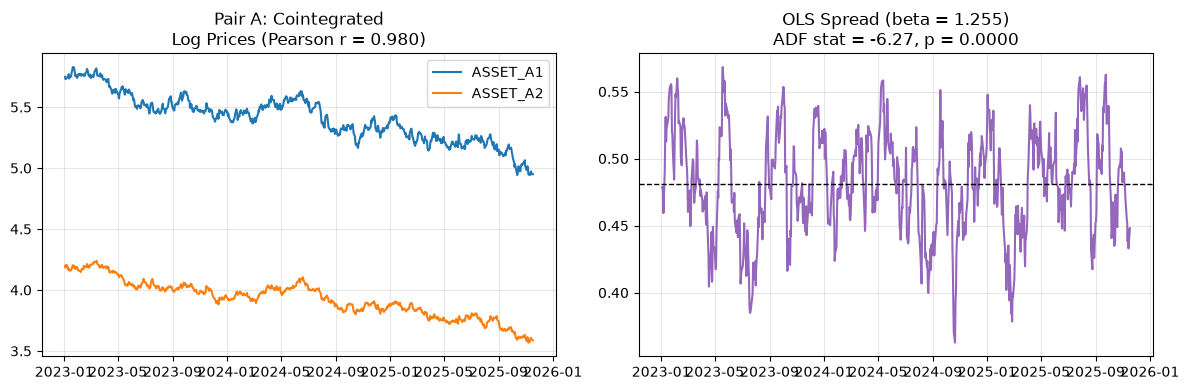

C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\2594110106.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(spread)


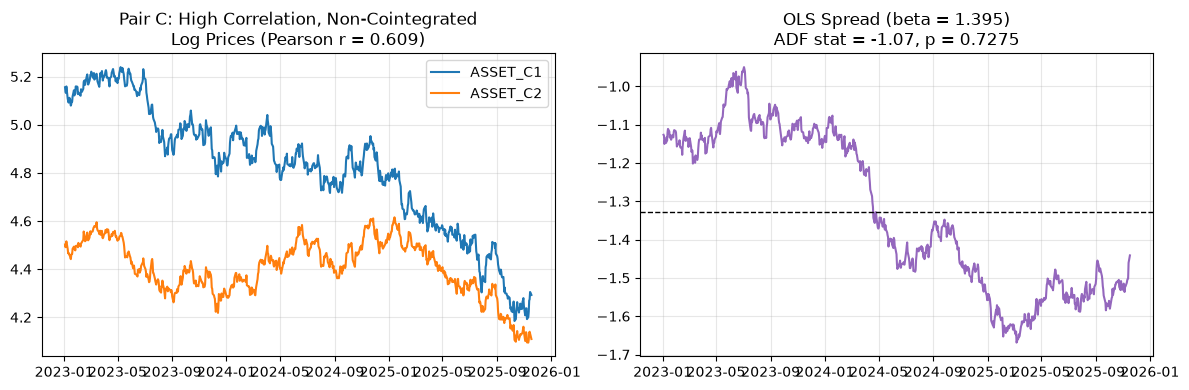

In [2]:
def compare_correlation_vs_spread(log_df: pd.DataFrame, a: str, b: str, title: str):
    corr = log_df[a].corr(log_df[b])
    X = sm.add_constant(log_df[b])
    model = sm.OLS(log_df[a], X).fit()
    beta = model.params[b]
    spread = log_df[a] - beta * log_df[b]
    adf_stat, p_val, *_ = adfuller(spread)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(log_df.index, log_df[a], label=a)
    axes[0].plot(log_df.index, log_df[b], label=b)
    axes[0].set_title(f'{title}\nLog Prices (Pearson r = {corr:.3f})')
    axes[0].legend()

    axes[1].plot(spread.index, spread, color='tab:purple')
    axes[1].axhline(spread.mean(), color='black', linestyle='--', linewidth=1)
    axes[1].set_title(f'OLS Spread (beta = {beta:.3f})\nADF stat = {adf_stat:.2f}, p = {p_val:.4f}')

    plt.tight_layout()
    plt.show()

compare_correlation_vs_spread(log_prices, 'ASSET_A1', 'ASSET_A2', 'Pair A: Cointegrated')
compare_correlation_vs_spread(log_prices, 'ASSET_C1', 'ASSET_C2', 'Pair C: High Correlation, Non-Cointegrated')

## 2. Engle-Granger Cointegration Screening & Half-Life Estimation

### Steps
1. Regress $y_t = \log P_{A,t}$ on $x_t = \log P_{B,t}$ via OLS: $y_t = \alpha + \beta x_t + \epsilon_t$.
2. Run an Augmented Dickey-Fuller (ADF) test on the residual spread $s_t = y_t - \hat{\beta} x_t$.
3. Estimate the mean-reversion half-life $t_{1/2}$ from an AR(1) regression on $\Delta s_t = s_t - s_{t-1}$:
   $$\Delta s_t = \alpha_{\text{ar}} + \theta s_{t-1} + \eta_t \implies t_{1/2} = -\frac{\ln(2)}{\ln(1 + \theta)}$$

*Note on multiple testing:* Screening $\binom{N}{2}$ pairs tests dozens of hypotheses simultaneously. Always inspect both p-values and economic/sector rationale.

In [3]:
def estimate_half_life(spread: pd.Series) -> float:
    s_lag = spread.shift(1).dropna()
    ds = spread.diff().dropna()
    s_lag, ds = s_lag.align(ds, join='inner')
    X = sm.add_constant(s_lag)
    res = sm.OLS(ds, X).fit()
    theta = res.params.iloc[1]
    if theta >= 0 or (1 + theta) <= 0:
        return np.nan
    return float(-np.log(2) / np.log(1 + theta))

def screen_pairs(log_df: pd.DataFrame, max_half_life: float = 45.0) -> pd.DataFrame:
    cols = list(log_df.columns)
    rows = []
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            a, b = cols[i], cols[j]
            X = sm.add_constant(log_df[b])
            ols_res = sm.OLS(log_df[a], X).fit()
            beta = float(ols_res.params[b])
            spread = log_df[a] - beta * log_df[b]
            adf_stat, p_val, *_ = adfuller(spread)
            hl = estimate_half_life(spread)
            rows.append({
                'leg_a': a,
                'leg_b': b,
                'beta': beta,
                'adf_stat': adf_stat,
                'p_value': p_val,
                'half_life_days': hl,
            })
    df_res = pd.DataFrame(rows).sort_values('p_value')
    return df_res

screened = screen_pairs(log_prices)
print('Top 10 pairs by ADF p-value:')
print(screened.head(10).to_string(index=False))

candidates = screened[(screened['p_value'] < 0.05) & (screened['half_life_days'].between(2, 45))]
print(f'\nFiltered candidates (p < 0.05, 2 <= half_life <= 45): {len(candidates)}')
print(candidates.to_string(index=False))

C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\1584791736.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(spread)
C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\1584791736.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(spread)
C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\1584791736.py:22: 

Top 10 pairs by ADF p-value:
   leg_a    leg_b     beta  adf_stat      p_value  half_life_days
ASSET_A1 ASSET_A2 1.255103 -6.266455 4.102760e-08        8.239869
ASSET_B1 ASSET_B2 0.882286 -4.044861 1.192991e-03       15.070965
ASSET_B1 ASSET_D2 0.222084 -3.908683 1.971865e-03       17.053227
ASSET_B1 ASSET_D3 0.266313 -3.868742 2.277321e-03       16.957845
ASSET_B1 ASSET_C2 0.342005 -3.753454 3.421104e-03       18.379369
ASSET_B2 ASSET_D3 0.308348 -3.617655 5.432343e-03       20.030885
ASSET_B1 ASSET_C1 0.038199 -3.527805 7.301070e-03       20.094464
ASSET_B1 ASSET_D4 0.064122 -3.522047 7.438598e-03       20.241540
ASSET_B1 ASSET_D1 0.066416 -3.467286 8.868099e-03       20.533574
ASSET_B2 ASSET_D2 0.283021 -3.387581 1.138960e-02       19.457666

Filtered candidates (p < 0.05, 2 <= half_life <= 45): 14
   leg_a    leg_b      beta  adf_stat      p_value  half_life_days
ASSET_A1 ASSET_A2  1.255103 -6.266455 4.102760e-08        8.239869
ASSET_B1 ASSET_B2  0.882286 -4.044861 1.192991e-03   

C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\1584791736.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(spread)
C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\1584791736.py:22: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, p_val, *_ = adfuller(spread)
C:\Users\oviya\AppData\Local\Temp\ipykernel_17700\1584791736.py:22: 

## 3. Signal Generation, Execution Lag & Leak-Free Backtest

### Critical Backtest Rules
- **No lookahead:** Compute rolling mean $\mu_{\text{roll}, t}$ and rolling std $\sigma_{\text{roll}, t}$ strictly from past observations.
- **Execution lag:** Decisions made at close $t$ execute at $t+1$ (`positions = signal.shift(1)`).
- **Transaction costs:** Charge proportional round-trip/turnover costs on position changes: `cost_bps * 1e-4 * |pos_t - pos_{t-1}|`.

Pair A Backtest Summary:
total_net_return    0.028455
ann_sharpe_net      0.142563
max_drawdown_net   -0.077629
dtype: float64


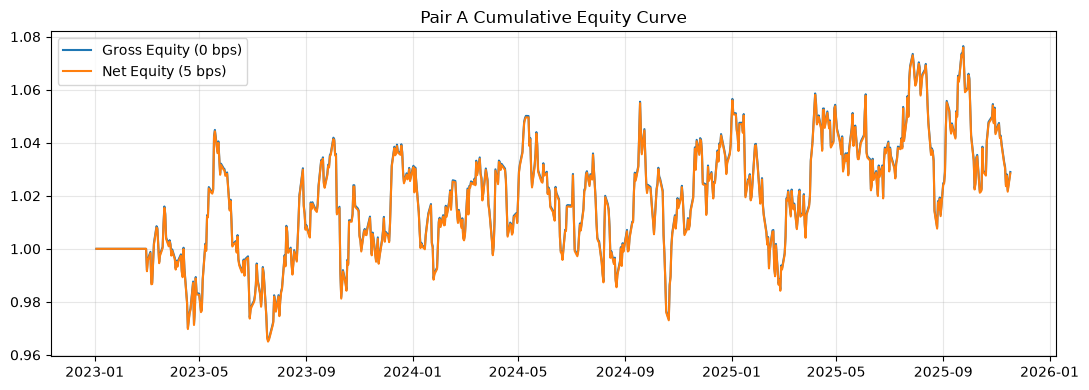

In [4]:
def backtest_pair(
    prices_df: pd.DataFrame,
    leg_a: str,
    leg_b: str,
    lookback: int = 30,
    z_entry: float = 2.0,
    z_exit: float = 0.0,
    cost_bps: float = 5.0,
) -> pd.DataFrame:
    log_df = np.log(prices_df[[leg_a, leg_b]])
    ret_a = prices_df[leg_a].pct_change().fillna(0.0)
    ret_b = prices_df[leg_b].pct_change().fillna(0.0)

    # Static hedge ratio estimated on initial window to avoid full-sample lookahead
    init_slice = log_df.iloc[:250]
    X_init = sm.add_constant(init_slice[leg_b])
    beta = float(sm.OLS(init_slice[leg_a], X_init).fit().params[leg_b])

    spread = log_df[leg_a] - beta * log_df[leg_b]
    roll_mean = spread.rolling(lookback).mean()
    roll_std = spread.rolling(lookback).std()
    z_score = (spread - roll_mean) / roll_std

    # State machine for long/short spread positions
    pos = np.zeros(len(spread))
    curr = 0.0
    for i, z in enumerate(z_score.values):
        if np.isnan(z):
            curr = 0.0
        elif curr == 0.0:
            if z > z_entry:
                curr = -1.0  # Short spread: short A, long beta * B
            elif z < -z_entry:
                curr = 1.0   # Long spread: long A, short beta * B
        else:
            if abs(z) <= z_exit:
                curr = 0.0
        pos[i] = curr

    positions = pd.Series(pos, index=spread.index).shift(1).fillna(0.0)
    turnover = positions.diff().abs().fillna(positions.abs())

    # Dollar-neutralized leg weights
    gross_ret = positions * (ret_a - beta * ret_b) / (1.0 + abs(beta))
    tx_cost = turnover * (cost_bps * 1e-4)
    net_ret = gross_ret - tx_cost

    return pd.DataFrame({
        'spread': spread,
        'z_score': z_score,
        'position': positions,
        'gross_ret': gross_ret,
        'net_ret': net_ret,
        'cum_gross': (1 + gross_ret).cumprod(),
        'cum_net': (1 + net_ret).cumprod(),
    })

def summarize_performance(bt: pd.DataFrame, ann_factor: int = 252) -> pd.Series:
    r = bt['net_ret']
    sharpe = np.sqrt(ann_factor) * r.mean() / (r.std() + 1e-12)
    eq = bt['cum_net']
    drawdown = (eq / eq.cummax() - 1.0).min()
    total_return = eq.iloc[-1] - 1.0
    return pd.Series({
        'total_net_return': total_return,
        'ann_sharpe_net': sharpe,
        'max_drawdown_net': drawdown,
    })

bt_a = backtest_pair(prices, 'ASSET_A1', 'ASSET_A2', lookback=20, z_entry=1.8, cost_bps=5.0)
print('Pair A Backtest Summary:')
print(summarize_performance(bt_a))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bt_a.index, bt_a['cum_gross'], label='Gross Equity (0 bps)')
ax.plot(bt_a.index, bt_a['cum_net'], label='Net Equity (5 bps)')
ax.set_title('Pair A Cumulative Equity Curve')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Failure Mode Stress Test: Structural Break

A pair cointegrated over 3 years can break overnight due to an acquisition, regulatory shift, or capital structure change. Below we inject a permanent structural shift into `ASSET_A1` at day 550 and observe what happens to a static-hedge spread.

Stressed Pair A Summary (with structural drift break at day 550):
total_net_return   -0.225466
ann_sharpe_net     -0.769308
max_drawdown_net   -0.270440
dtype: float64


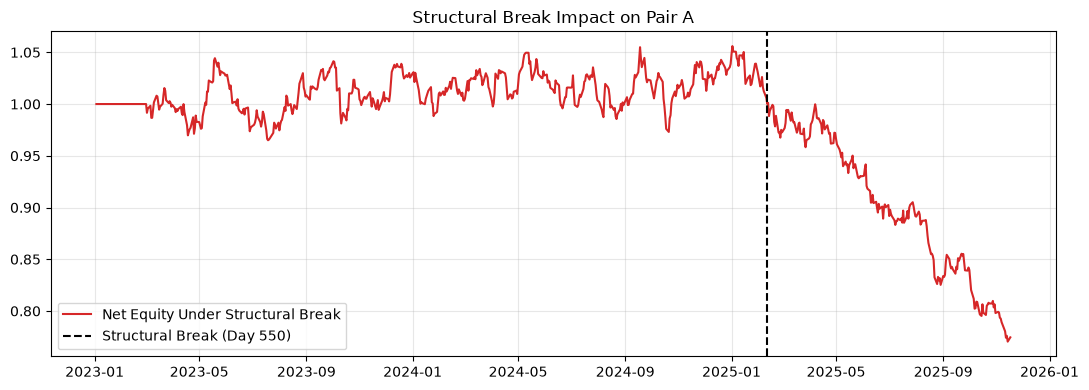

In [5]:
stressed_prices = prices.copy()
n_post = len(stressed_prices) - 550
# Permanent regime drift in ASSET_A2 starting at day 550 breaks the historical spread relationship
drift = np.exp(np.cumsum(np.full(n_post, 0.0025)))
stressed_prices.iloc[550:, stressed_prices.columns.get_loc('ASSET_A2')] *= drift

bt_stressed = backtest_pair(stressed_prices, 'ASSET_A1', 'ASSET_A2', lookback=20, z_entry=1.8, cost_bps=5.0)
print('Stressed Pair A Summary (with structural drift break at day 550):')
print(summarize_performance(bt_stressed))

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(bt_stressed.index, bt_stressed['cum_net'], color='tab:red', label='Net Equity Under Structural Break')
ax.axvline(prices.index[550], color='black', linestyle='--', label='Structural Break (Day 550)')
ax.set_title('Structural Break Impact on Pair A')
ax.legend()
plt.tight_layout()
plt.show()


## 5. Live Mini-Challenge (15 Minutes)

Modify `backtest_pair` or write a wrapper below to test:
1. **Rolling hedge ratio** $\hat{\beta}_t$ (e.g., 120-day rolling OLS) instead of a fixed initial slice.
2. **In-sample vs. out-of-sample split** (fit parameters on first 70% of dates, evaluate on final 30%).
3. **Transaction cost sensitivity** across `0 bps`, `5 bps`, and `15 bps`.

In [6]:
# TODO (Mini-Challenge):
# 1. Replace static beta with a 120-day rolling OLS slope.
# 2. Split at int(0.7 * len(prices)) and compare OOS Sharpe across cost_bps in [0, 5, 15].
# 3. Add a stop-loss rule (e.g., exit if |z_score| > 3.5) and compare max drawdown.
pass